# Iteration 2.5: KNN & Decision Trees
### Open Minds Club · AI School

### By: BOULGHERAIF Fatma Zohra

---
## Setup

In [59]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.inspection import DecisionBoundaryDisplay

# reproducibility
np.random.seed(42)
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.size': 11
})

COLORS = ['#2563EB', '#10B981', '#F59E0B']   # blue, green, amber
CMAP   = ListedColormap(['#BFDBFE', '#A7F3D0', '#FDE68A'])
CLASS_NAMES = ['Setosa', 'Versicolor', 'Virginica']


---
## Dataset

We use the **Iris dataset** throughout: 150 samples, 3 classes (Setosa, Versicolor, Virginica), 4 features.

For all 2-D visualisations we project onto **petal length × petal width** — the two most discriminative features in the dataset. This keeps every figure directly comparable.

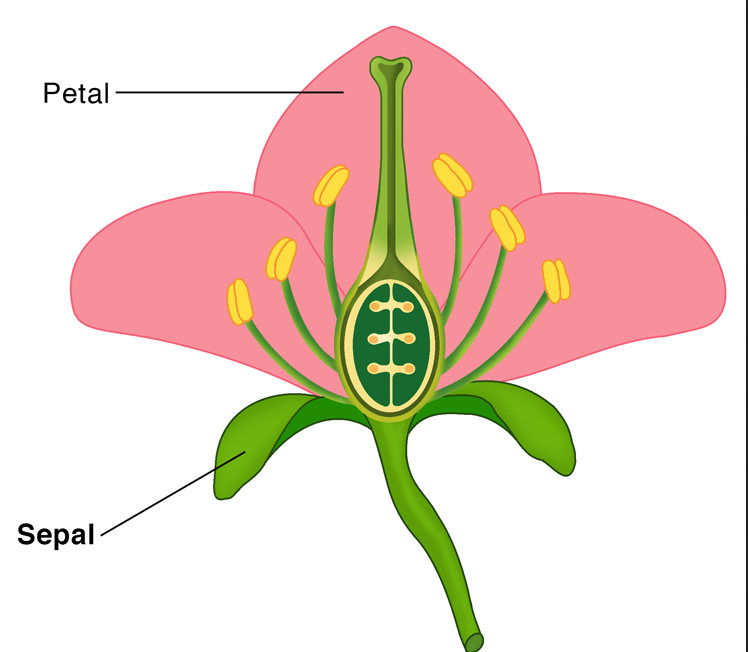


In [60]:
# Load data
iris = load_iris()
X = iris.data
y = iris.target
df = pd.DataFrame(X, columns=iris.feature_names)
df['species'] = [CLASS_NAMES[i] for i in y]

print(f"Shape: {X.shape}")
print(f"Classes: {CLASS_NAMES}")
print(f"Class counts:\n{df['species'].value_counts()}")
df.head()


Shape: (150, 4)
Classes: ['Setosa', 'Versicolor', 'Virginica']
Class counts:
Setosa        50
Versicolor    50
Virginica     50
Name: species, dtype: int64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa


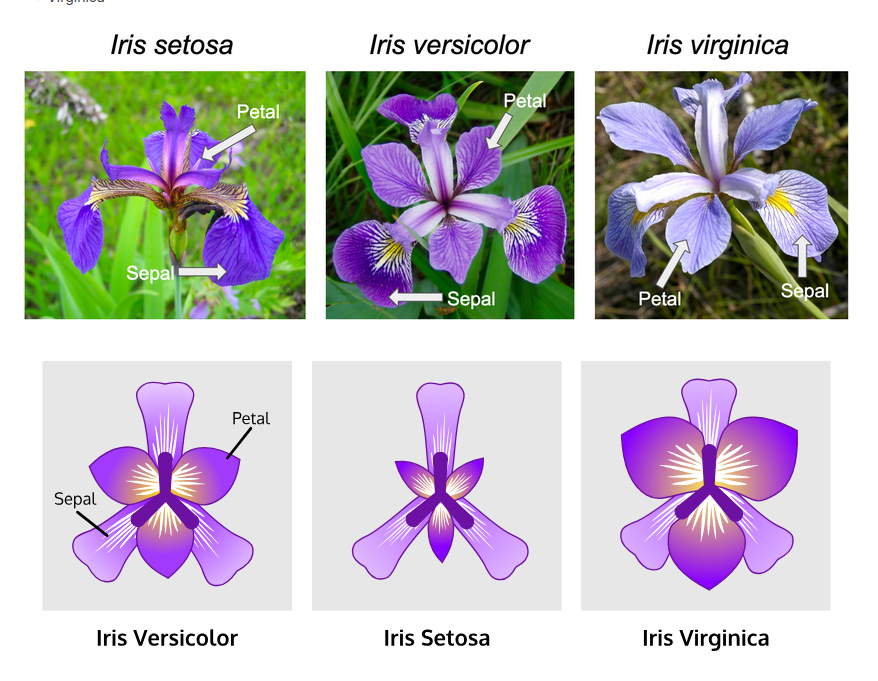

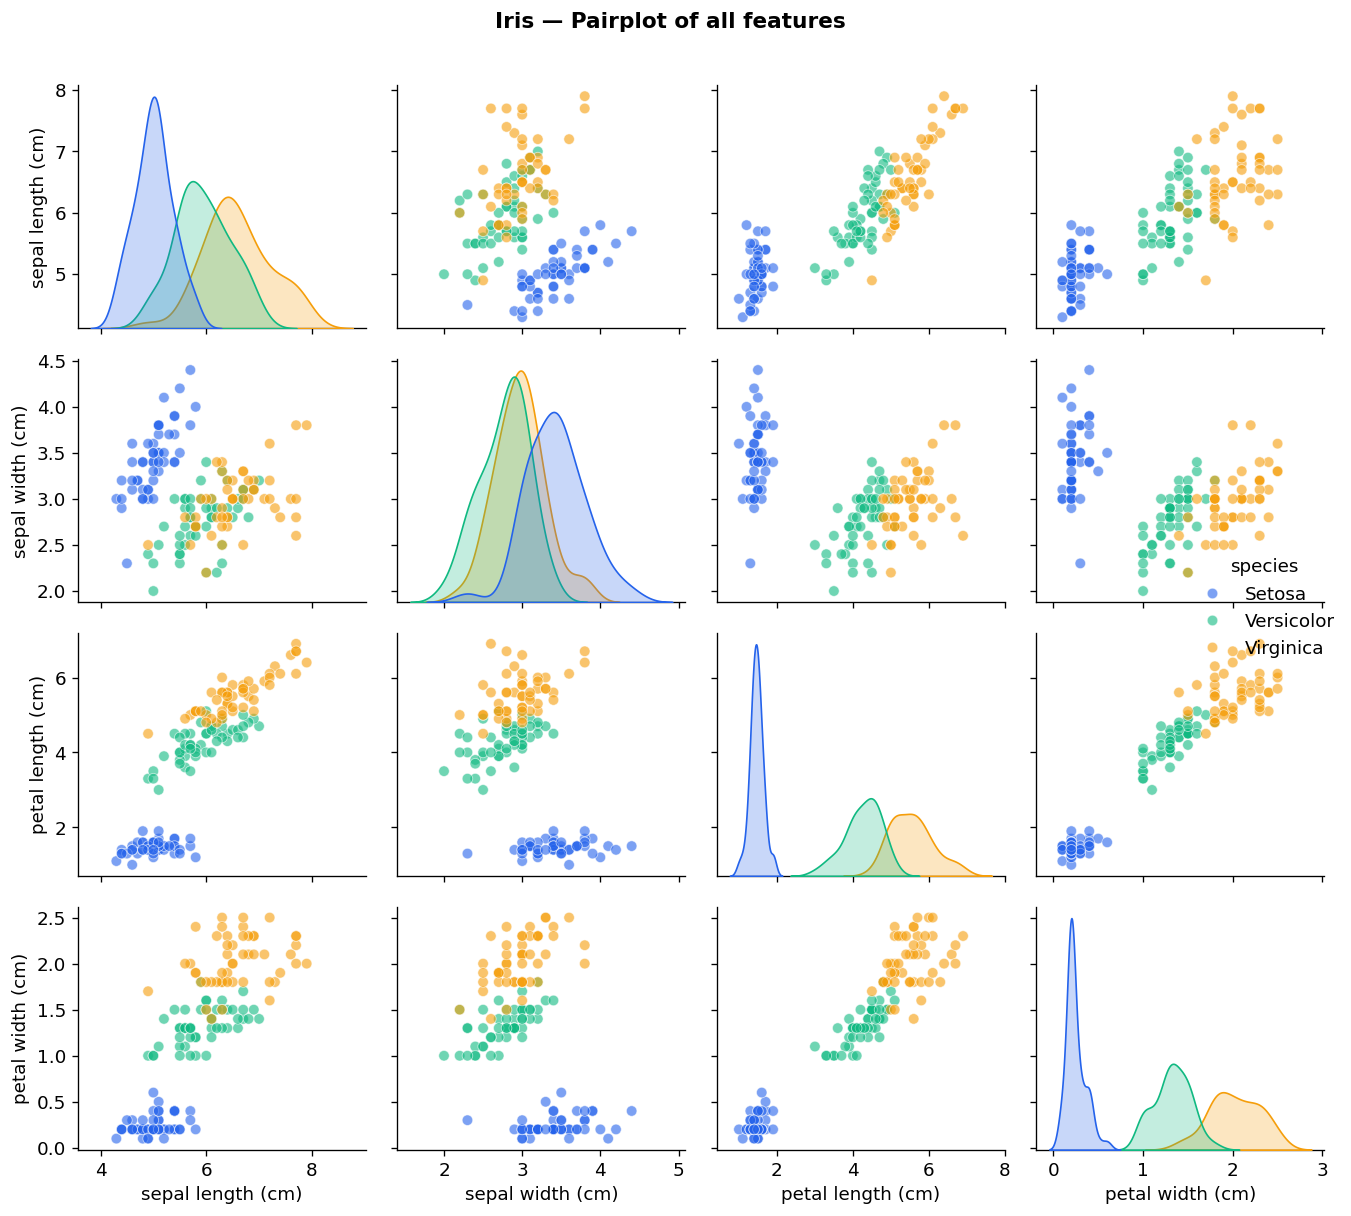

In [61]:
# Pairplot — quick EDA
g = sns.pairplot(df, hue='species', palette=dict(zip(CLASS_NAMES, COLORS)),
                 diag_kind='kde', plot_kws={'alpha': 0.6, 's': 40})
g.fig.suptitle("Iris — Pairplot of all features", y=1.01, fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


In [62]:
# We use features 2 & 3 for all 2-D figures
X = X[:, 2:]   # petal length, petal width
feat_names = ['Petal length (cm)', 'Petal width (cm)']

# Train / test split (stratified)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

print(f"Train: {X_tr.shape[0]} samples  |  Test: {X_te.shape[0]} samples")


Train: 112 samples  |  Test: 38 samples


In [63]:
# Feature scaling — REQUIRED for KNN (apply now, use for all KNN sections)
scaler = StandardScaler()

X_tr_sc   = scaler.fit_transform(X_tr)
X_te_sc   = scaler.transform(X_te)


---
## KNN: K-Nearest Neighbors

KNN is a **non-parametric, instance-based, distance-based** learner.

- **Non-parametric:** makes no assumptions about the underlying data distribution. The decision boundary is learned entirely from the data.
- **Instance-based:** there is no training phase. The model is the training data itself. All computation is deferred to prediction time.
- **Distance-based:** prediction is driven by proximity. The K nearest neighbours are found by computing distances from the query point to every training example, then aggregating their labels.

kNN is called a **lazy** learner because it has no training phase.


Playground: https://k-nearest-neighbors.vercel.app/


### Forward Pass
Pseudo code: Query point i
1. Look at every point in the training set.
2. Compute its distance to the query point.
3. Store that distance together with the point's label.
4. Sort all stored distances from smallest to largest.
5. Keep only the first k.
6. Look at their labels.
7. Return the most common label for classification.

### Distance Metrics

"Closeness" is defined by a distance function. The two most common:

| Metric | Formula |
|--------|---------|
| **Euclidean** | $d = \sqrt{\sum (x_i - y_i)^2}$ |
| **Manhattan** | $d = \sum \|x_i - y_i\|$ |

Both are generalizations of the **Minkowski Distance**, defined as:

$$d(x, y) = \left( \sum_{i=1}^{n} |x_i - y_i|^p \right)^{1/p}$$

Setting $p = 1$ recovers the Manhattan distance; setting $p = 2$ recovers the Euclidean distance. 

**Feature scaling is mandatory.** A feature measured in centimetres will dominate one measured in millimetres, distances become meaningless. We applied `StandardScaler` in Section 0.


In [64]:
knn_full = KNeighborsClassifier(n_neighbors=3)
knn_full.fit(X_tr_sc, y_tr)
y_pred_knn = knn_full.predict(X_te_sc)

print("=" * 45)
print(f"Classification Report")
print("=" * 45)
print(classification_report(y_te, y_pred_knn, target_names=CLASS_NAMES))


Classification Report
              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        12
  Versicolor       1.00      0.92      0.96        13
   Virginica       0.93      1.00      0.96        13

    accuracy                           0.97        38
   macro avg       0.98      0.97      0.97        38
weighted avg       0.98      0.97      0.97        38



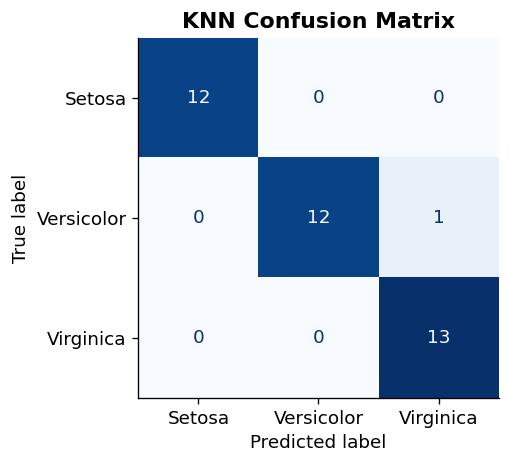

In [65]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_te, y_pred_knn, display_labels=CLASS_NAMES,
    colorbar=False, cmap='Blues', ax=ax
)
ax.set_title(f'KNN Confusion Matrix', fontweight='bold')
plt.tight_layout()
plt.show()


### Effect of K (Bias-Variance Trade-off)

K is the single most important hyperparameter in KNN.

| K | Bias | Variance | Boundary |
|---|------|----------|----------|
| K = 1 | Very low | Very high | Jagged, overfits |
| K = n | Very high | Very low | Predicts majority class everywhere |
| Optimal K | Balanced | Balanced | Smooth and generalises |


### Worked Example

We have 5 samples from the Iris dataset. The query point is $(1.4, 0.2)$ and $K = 3$. Features are petal length and petal width only.

| Point | Petal L | Petal W | Label |
|-------|---------|---------|-------|
| A | 1.4 | 0.2 | Setosa |
| B | 3.6 | 1.3 | Versicolor |
| C | 1.5 | 0.2 | Setosa |
| D | 4.7 | 1.6 | Virginica |
| E | 3.9 | 1.2 | Versicolor |

**Step 1–3.** Compute Euclidean distance from each point to $(1.4, 0.2)$.

| Point | Calculation | Distance |
|-------|-------------|----------|
| A | $\sqrt{(1.4-1.4)^2 + (0.2-0.2)^2}$ | $0.00$ |
| B | $\sqrt{(1.4-3.6)^2 + (0.2-1.3)^2}$ | $2.46$ |
| C | $\sqrt{(1.4-1.5)^2 + (0.2-0.2)^2}$ | $0.10$ |
| D | $\sqrt{(1.4-4.7)^2 + (0.2-1.6)^2}$ | $3.59$ |
| E | $\sqrt{(1.4-3.9)^2 + (0.2-1.2)^2}$ | $2.69$ |

**Step 4–5.** Sort and keep the 3 nearest.

| Rank | Point | Distance | Label |
|------|-------|----------|-------|
| 1 | A | 0.00 | Setosa |
| 2 | C | 0.10 | Setosa |
| 3 | B | 2.46 | Versicolor |

**Step 6–7.** Tally the labels: Setosa appears twice, Versicolor once. The predicted class is **Setosa**.

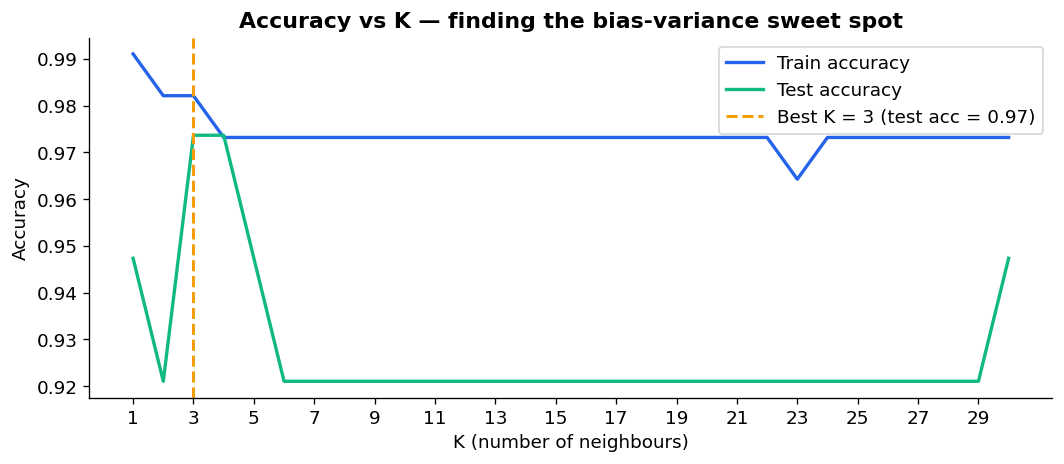

Best K on test set: 3  |  Test accuracy: 0.974


In [ ]:
# Accuracy vs K curve
k_values = range(1, 31)
train_acc, val_acc = [], []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_tr_sc, y_tr)
    train_acc.append(knn.score(X_tr_sc, y_tr))
    val_acc.append(knn.score(X_te_sc, y_te))

best_k = k_values[np.argmax(val_acc)]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(k_values, train_acc, label='Train accuracy', color='#2563EB', linewidth=2)
ax.plot(k_values, val_acc,   label='Test accuracy',  color='#10B981', linewidth=2)
ax.axvline(best_k, color='#F59E0B', linestyle='--', linewidth=1.8,
           label=f'Best K = {best_k} (test acc = {max(val_acc):.2f})')
ax.set_xlabel('K (number of neighbours)')
ax.set_ylabel('Accuracy')
ax.set_title('Accuracy vs K — finding the bias-variance sweet spot', fontweight='bold')
ax.legend()
ax.set_xticks(range(1, 31, 2))
plt.tight_layout()
plt.show()
print(f"Best K on test set: {best_k}  |  Test accuracy: {max(val_acc):.3f}")


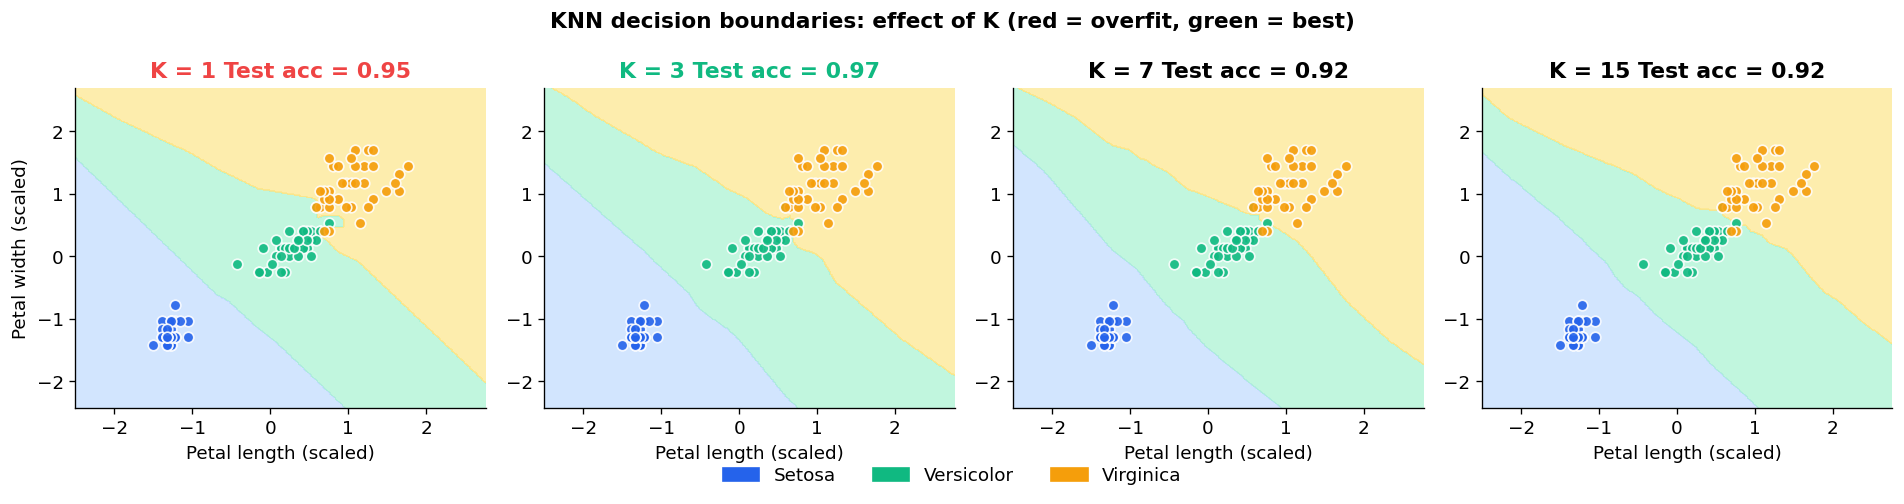

In [67]:
# Decision boundaries for K = 1, 3, 7, 15
ks_to_show = [1, 3, 7, 15]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, k in zip(axes, ks_to_show):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_tr_sc, y_tr)

    DecisionBoundaryDisplay.from_estimator(
        knn, X_tr_sc, ax=ax, cmap=CMAP, alpha=0.7,
        response_method='predict', grid_resolution=300
    )
    for cls, color, name in zip([0,1,2], COLORS, CLASS_NAMES):
        mask = y_tr == cls
        ax.scatter(X_tr_sc[mask,0], X_tr_sc[mask,1],
                   color=color, edgecolors='white', s=40, alpha=0.9)
    
    test_acc = knn.score(X_te_sc, y_te)
    title_color = '#EF4444' if k == 1 else ('#10B981' if k == best_k else 'black')
    ax.set_title(f'K = {k} Test acc = {test_acc:.2f}',
                 fontweight='bold', color=title_color)
    ax.set_xlabel('Petal length (scaled)')
    if k == 1: ax.set_ylabel('Petal width (scaled)')

patches = [mpatches.Patch(color=c, label=n) for c, n in zip(COLORS, CLASS_NAMES)]
fig.legend(handles=patches, loc='lower center', ncol=3, frameon=False,
           bbox_to_anchor=(0.5, -0.04))
plt.suptitle('KNN decision boundaries: effect of K (red = overfit, green = best)', 
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


---
Decision Boundary at Optimal K

A clean look at the boundary produced by the best K, with both training and test points shown.


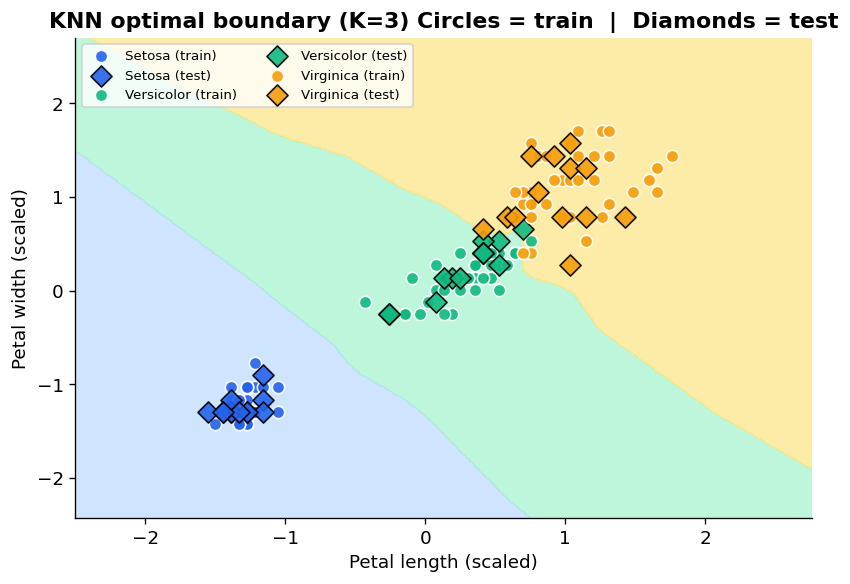

In [68]:
fig, ax = plt.subplots(figsize=(7, 5))

knn_best = KNeighborsClassifier(n_neighbors=best_k)
knn_best.fit(X_tr_sc, y_tr)

DecisionBoundaryDisplay.from_estimator(
    knn_best, X_tr_sc, ax=ax, cmap=CMAP, alpha=0.75,
    response_method='predict', grid_resolution=400
)

# train points
for cls, color, name in zip([0,1,2], COLORS, CLASS_NAMES):
    mask_tr = y_tr == cls
    mask_te = y_te == cls
    ax.scatter(X_tr_sc[mask_tr,0], X_tr_sc[mask_tr,1],
               color=color, edgecolors='white', s=55, alpha=0.9, label=f'{name} (train)')
    ax.scatter(X_te_sc[mask_te,0], X_te_sc[mask_te,1],
               color=color, edgecolors='black', s=80, marker='D', alpha=0.9, label=f'{name} (test)')

ax.set_xlabel('Petal length (scaled)')
ax.set_ylabel('Petal width (scaled)')
ax.set_title(f'KNN optimal boundary (K={best_k}) Circles = train  |  Diamonds = test',
             fontweight='bold')
ax.legend(fontsize=8, loc='upper left', ncol=2)
plt.tight_layout()
plt.show()


### KNN Limitations

| Limitation | Detail |
|------------|--------|
| **Slow at inference** | Every prediction scans the entire training set <=> O(n·d) per query (n: number of instances, d: number of features). Unusable for large n. |
| **Sensitive to irrelevant features** | Noise features dilute signal in distance computation. Feature selection helps. |
| **Requires scaling** | |
| **Curse of dimensionality** | In high dimensions, all points become roughly equidistant. The concept of "nearest neighbour" loses meaning. KNN degrades rapidly beyond ~20 features. |


For binary classification, k must be odd.

> **Regression note:** In KNN regression the majority vote becomes an **average** — the predicted value is the mean of the K neighbours' target values. Everything else (distance function, K selection, scaling requirement) is identical.

---
## Decision Trees

A Decision Tree learns a **hierarchy of binary rules** on the features.

- Each **internal node** = a split condition: *feature ≤ threshold?*
- Each **leaf** = a class prediction
- The tree is learned greedily: at each node, pick the split that maximally reduces impurity

Unlike KNN, a Decision Tree produces **an explicit, readable model**, you can print the rules.

The figure below shows a small toy tree to build intuition before we fit one on Iris.


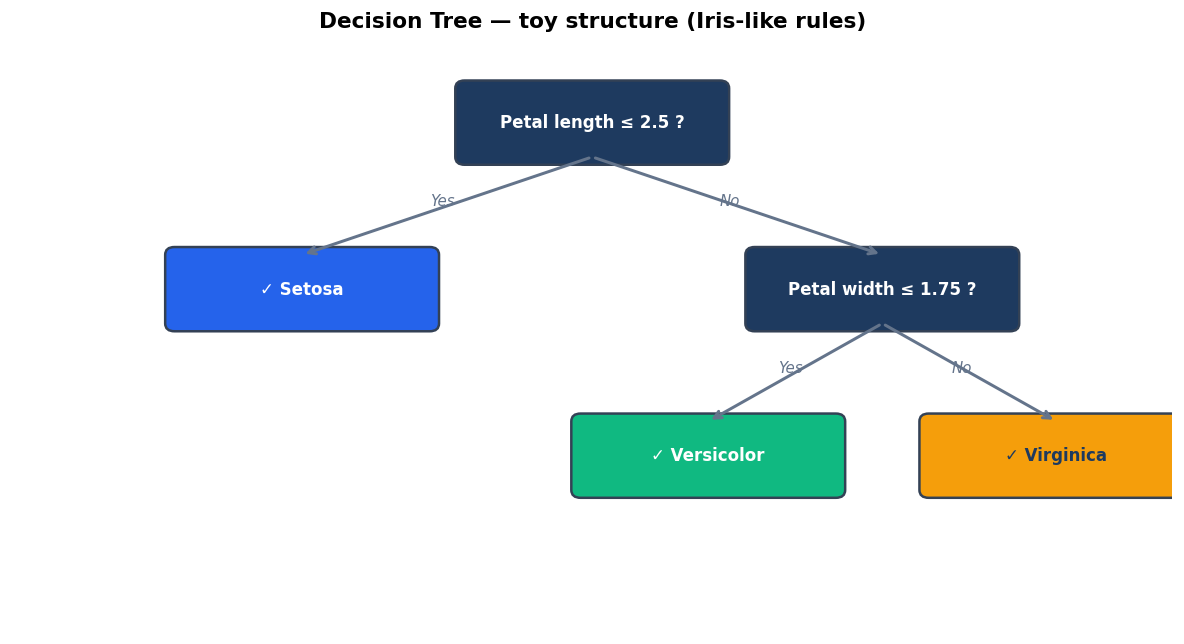

In [69]:
# Hand-drawn style toy tree diagram
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.set_xlim(0, 10); ax.set_ylim(0, 6)
ax.axis('off')
ax.set_facecolor('white')

def draw_node(ax, x, y, text, color='#1E3A5F', textcolor='white', fontsize=10, width=2.2, height=0.7):
    rect = mpatches.FancyBboxPatch((x - width/2, y - height/2), width, height,
                                    boxstyle="round,pad=0.08", linewidth=1.5,
                                    edgecolor='#334155', facecolor=color)
    ax.add_patch(rect)
    ax.text(x, y, text, ha='center', va='center', fontsize=fontsize,
            color=textcolor, fontweight='bold', wrap=True,
            multialignment='center')

def draw_edge(ax, x1, y1, x2, y2, label='', color='#64748B'):
    ax.annotate('', xy=(x2, y2+0.35), xytext=(x1, y1-0.35),
                arrowprops=dict(arrowstyle='->', color=color, lw=1.8))
    mx, my = (x1+x2)/2, (y1+y2)/2
    if label:
        ax.text(mx - 0.15, my, label, fontsize=9, color=color, fontstyle='italic')

# Root
draw_node(ax, 5, 5.2, 'Petal length ≤ 2.5 ?', color='#1E3A5F')

# Level 1
draw_node(ax, 2.5, 3.5, '✓ Setosa', color='#2563EB')
draw_node(ax, 7.5, 3.5, 'Petal width ≤ 1.75 ?', color='#1E3A5F')

draw_edge(ax, 5, 5.2, 2.5, 3.5, 'Yes')
draw_edge(ax, 5, 5.2, 7.5, 3.5, 'No')

# Level 2
draw_node(ax, 6.0, 1.8, '✓ Versicolor', color='#10B981')
draw_node(ax, 9.0, 1.8, '✓ Virginica',  color='#F59E0B', textcolor='#1E3A5F')

draw_edge(ax, 7.5, 3.5, 6.0, 1.8, 'Yes')
draw_edge(ax, 7.5, 3.5, 9.0, 1.8, 'No')

ax.set_title('Decision Tree — toy structure (Iris-like rules)', 
             fontsize=13, fontweight='bold', pad=10)
plt.tight_layout()
plt.show()


---
### Tree Depth 

An unrestricted tree memorises the training set, every leaf ends up with a single sample. `max_depth` is the primary regularisation knob.

**First:** look at the train/test accuracy curve and identify the elbow.  
**Then:** inspect the boundaries at different depths.


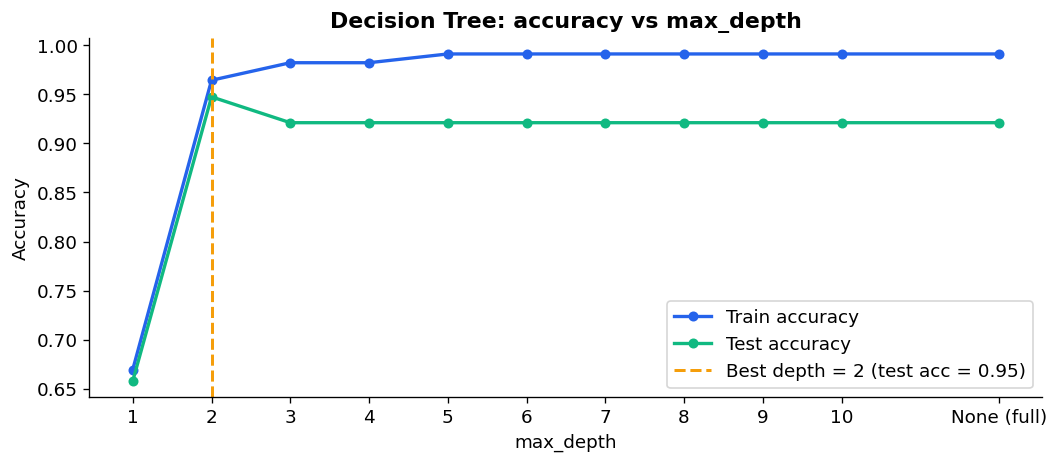

Best max_depth: 2  |  Test accuracy: 0.947


In [70]:
# Train/test accuracy vs max_depth
depths = list(range(1, 11)) + [None]
train_acc_dt, test_acc_dt = [], []

for d in depths:
    dt = DecisionTreeClassifier(max_depth=d, random_state=42)
    dt.fit(X_tr, y_tr)
    train_acc_dt.append(dt.score(X_tr, y_tr))
    test_acc_dt.append(dt.score(X_te, y_te))

x_ticks = list(range(1, 11)) + [12]
labels  = [str(d) for d in range(1, 11)] + ['None (full)']

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(x_ticks, train_acc_dt, label='Train accuracy', color='#2563EB', linewidth=2, marker='o', markersize=5)
ax.plot(x_ticks, test_acc_dt,  label='Test accuracy',  color='#10B981', linewidth=2, marker='o', markersize=5)

best_depth_idx = np.argmax(test_acc_dt)
best_depth = depths[best_depth_idx]
ax.axvline(x_ticks[best_depth_idx], color='#F59E0B', linestyle='--', linewidth=1.8,
           label=f'Best depth = {best_depth} (test acc = {max(test_acc_dt):.2f})')

ax.set_xticks(x_ticks); ax.set_xticklabels(labels)
ax.set_xlabel('max_depth'); ax.set_ylabel('Accuracy')
ax.set_title('Decision Tree: accuracy vs max_depth', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()
print(f"Best max_depth: {best_depth}  |  Test accuracy: {max(test_acc_dt):.3f}")


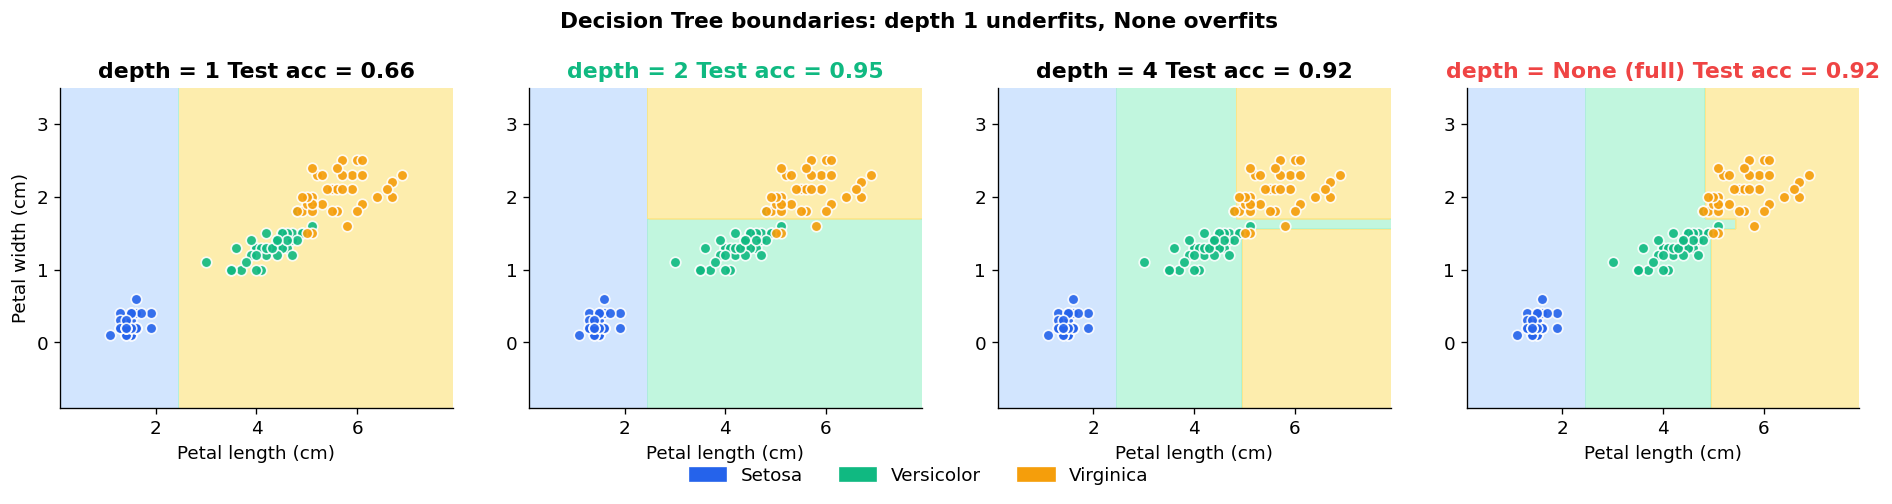

In [71]:
# Decision boundaries at depth 1, 2, 4, None (2-D petal features for visibility)
depths_show = [1, 2, 4, None]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, d in zip(axes, depths_show):
    dt = DecisionTreeClassifier(max_depth=d, random_state=42)
    dt.fit(X_tr, y_tr)

    DecisionBoundaryDisplay.from_estimator(
        dt, X_tr, ax=ax, cmap=CMAP, alpha=0.7,
        response_method='predict', grid_resolution=400
    )
    for cls, color, name in zip([0,1,2], COLORS, CLASS_NAMES):
        mask = y_tr == cls
        ax.scatter(X_tr[mask,0], X_tr[mask,1],
                   color=color, edgecolors='white', s=40, alpha=0.9)

    label = str(d) if d is not None else 'None (full)'
    test_acc_2d = dt.score(X_te, y_te)
    color = '#EF4444' if d is None else ('#10B981' if d == best_depth else 'black')
    ax.set_title(f'depth = {label} Test acc = {test_acc_2d:.2f}',
                 fontweight='bold', color=color)
    ax.set_xlabel('Petal length (cm)')
    if d == 1: ax.set_ylabel('Petal width (cm)')

patches = [mpatches.Patch(color=c, label=n) for c, n in zip(COLORS, CLASS_NAMES)]
fig.legend(handles=patches, loc='lower center', ncol=3, frameon=False,
           bbox_to_anchor=(0.5, -0.04))
plt.suptitle('Decision Tree boundaries: depth 1 underfits, None overfits',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


---
### Visualising the Tree & Feature Importance

One of the biggest advantages of Decision Trees: **you can read the model**.

We fit at the optimal depth and inspect:
1. The full tree diagram
2. The text rule list
3. Feature importance scores


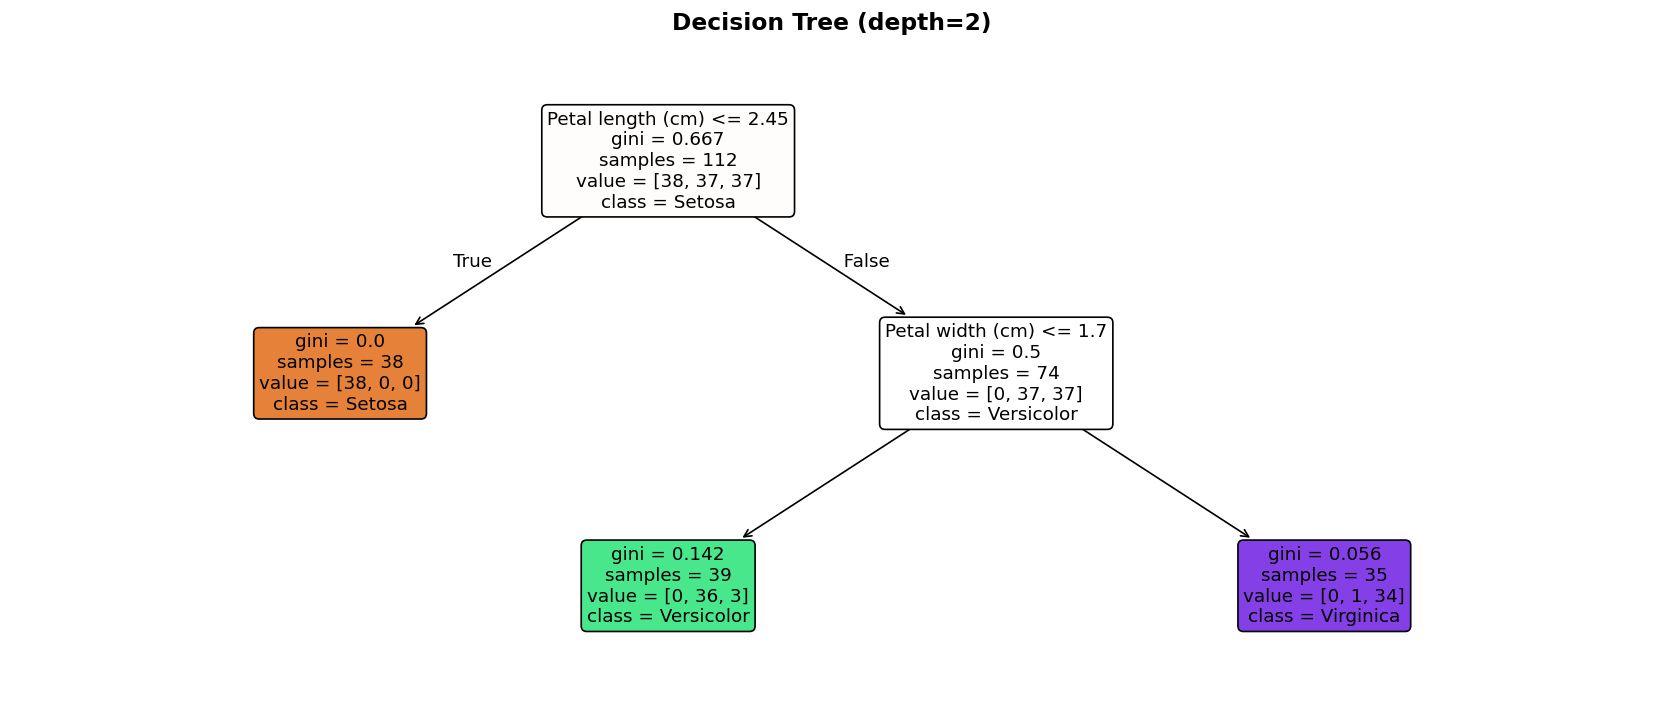

In [72]:
# Fit at best depth on 2-D features first (easier to read the tree)
dt_best2d = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
dt_best2d.fit(X_tr, y_tr)

fig, ax = plt.subplots(figsize=(14, 6))
plot_tree(
    dt_best2d,
    feature_names=feat_names,
    class_names=CLASS_NAMES,
    filled=True,
    rounded=True,
    impurity=True,
    proportion=False,
    fontsize=11,
    ax=ax,
    precision=3
)
ax.set_title(f'Decision Tree (depth={best_depth})',
             fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()


In [74]:
# Text rules — readable format
dt_best_full = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
dt_best_full.fit(X_tr, y_tr)

print("Decision Tree rules:")
print("=" * 60)
print(export_text(dt_best_full, feature_names=feat_names))


Decision Tree rules:
|--- Petal length (cm) <= 2.45
|   |--- class: 0
|--- Petal length (cm) >  2.45
|   |--- Petal width (cm) <= 1.70
|   |   |--- class: 1
|   |--- Petal width (cm) >  1.70
|   |   |--- class: 2



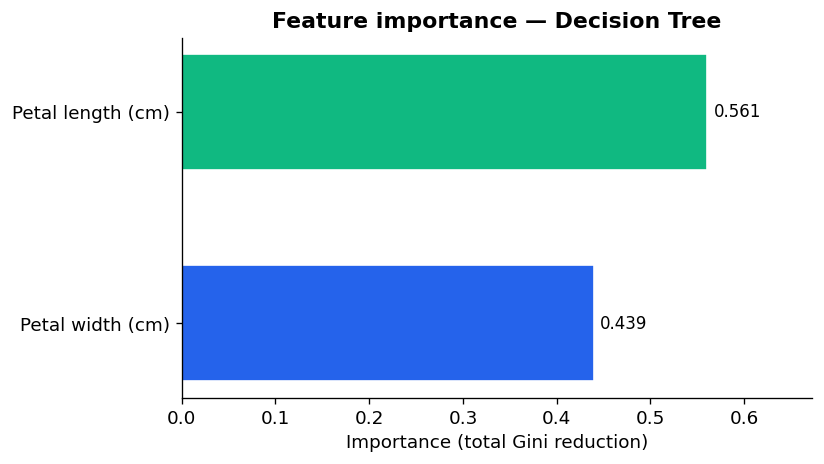

⚠  Note: impurity-based importance is biased toward high-cardinality features.
   For robust importance, prefer permutation importance on the test set.


In [76]:
# Feature importance bar chart
importances = dt_best_full.feature_importances_
feat_idx    = np.argsort(importances)   # ascending

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.barh(
    [feat_names[i] for i in feat_idx],
    importances[feat_idx],
    color=[COLORS[min(i, 2)] for i in range(len(feat_idx))],
    edgecolor='white', height=0.55
)
ax.bar_label(bars, fmt='%.3f', padding=4, fontsize=10)
ax.set_xlabel('Importance (total Gini reduction)')
ax.set_title('Feature importance — Decision Tree', fontweight='bold')
ax.set_xlim(0, importances.max() * 1.2)
plt.tight_layout()
plt.show()
print("⚠  Note: impurity-based importance is biased toward high-cardinality features.")
print("   For robust importance, prefer permutation importance on the test set.")


---
### Decision Tree: Full Evaluation


In [77]:
y_pred_dt = dt_best_full.predict(X_te)

print("=" * 45)
print(f"Decision Tree (depth={best_depth}) — Classification Report")
print("=" * 45)
print(classification_report(y_te, y_pred_dt, target_names=CLASS_NAMES))


Decision Tree (depth=2) — Classification Report
              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        12
  Versicolor       0.92      0.92      0.92        13
   Virginica       0.92      0.92      0.92        13

    accuracy                           0.95        38
   macro avg       0.95      0.95      0.95        38
weighted avg       0.95      0.95      0.95        38



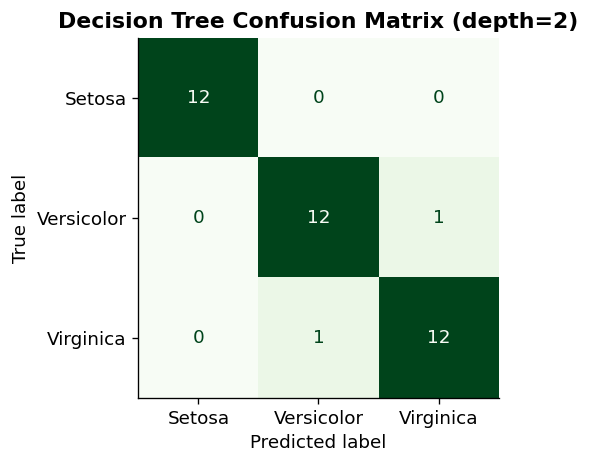

In [78]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_te, y_pred_dt, display_labels=CLASS_NAMES,
    colorbar=False, cmap='Greens', ax=ax
)
ax.set_title(f'Decision Tree Confusion Matrix (depth={best_depth})', fontweight='bold')
plt.tight_layout()
plt.show()


> **Regression note:** `DecisionTreeRegressor` uses the same splitting logic but predicts the **mean target value** of all training samples in each leaf. The impurity criterion becomes variance reduction (MSE) rather than Gini/Entropy. One-word swap: `DecisionTreeClassifier` → `DecisionTreeRegressor`.


---

### Summary of what we covered

```
KNN
├── Concept: vote from K nearest neighbours
├── Distance: Euclidean / Manhattan — scale your features!
├── K: low K = overfit, high K = underfit
└── Limits: slow inference, curse of dimensionality

Decision Tree
├── Concept: hierarchy of binary rules
├── Splitting: minimise Gini / Entropy at each node
├── Depth: primary regularisation knob
└── Strengths: interpretable, no scaling needed
```
